In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("Zomato data .csv", encoding ='latin1')

df.head()       
df.info()       
df.describe()   


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         148 non-null    object
 1   online_order                 148 non-null    object
 2   book_table                   148 non-null    object
 3   rate                         148 non-null    object
 4   votes                        148 non-null    int64 
 5   approx_cost(for two people)  148 non-null    int64 
 6   listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


,votes,approx_cost(for two people)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


In [2]:
df.describe()

,votes,approx_cost(for two people)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


In [3]:
df.rename(columns={'approx_cost(for two people)': 'cost', 'listed_in(type)': 'type'}, inplace=True)
type_counts= df ['type'].value_counts()
print("most popular restauranat type:",type_counts.max())
print("\nAll restaurent types count:\n", type_counts)

most popular restauranat type: 110

All restaurent types count:
 type
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64


In [4]:
df.rename(columns={'approx_cost(for two people)': 'cost', 'listed_in(type)': 'type'}, inplace=True)
votes_by_type = df.groupby('type')['votes'].sum().sort_values(ascending=False)
print(votes_by_type)


type
Dining    20363
other      9367
Cafes      6434
Buffet     3028
Name: votes, dtype: int64


In [5]:
df.rename(columns={'approx_cost(for two people)': 'cost', 'listed_in(type)': 'type'}, inplace=True)
votes_by_type = df.groupby('type')['votes'].sum().sort_values(ascending=False)
print(votes_by_type)


type
Dining    20363
other      9367
Cafes      6434
Buffet     3028
Name: votes, dtype: int64


In [6]:
df['rate'] = df['rate'].str.replace('/5', '', regex=False)
df['rate'] = df['rate'].replace(['NEW', '-', ''], np.nan).astype(float)
rating_counts = df['rate'].value_counts().sort_index()
print("Ratings and their counts:")
print(rating_counts)
most_common_rating = rating_counts.idxmax()
most_common_rating_count = rating_counts.max()
print(f"\nMost common rating: {most_common_rating} (received by {most_common_rating_count} restaurants)")


Ratings and their counts:
rate
2.6     1
2.8     2
2.9     7
3.0     2
3.1     7
3.2     7
3.3    14
3.4    12
3.5     6
3.6    11
3.7    15
3.8    20
3.9    10
4.0    10
4.1    11
4.2     8
4.3     1
4.4     2
4.6     2
Name: count, dtype: int64

Most common rating: 3.8 (received by 20 restaurants)


In [7]:

df.rename(columns={'approx_cost(for two people)': 'cost'}, inplace=True)
online_df = df[df['online_order'] == 'Yes']
average_spending = online_df['cost'].mean()
print(f"Average spending by online ordering customers: ₹{average_spending:.2f}")


Average spending by online ordering customers: ₹510.34


In [8]:
df['rate'] = df['rate'].replace('/5', '', regex=False)
df['rate'] = df['rate'].replace(['NEW', '-', ''], np.nan).astype(float)
avg_rating_by_mode = df.groupby('online_order')['rate'].mean()
print("Average rating by mode:")
print(avg_rating_by_mode)
max_mode = avg_rating_by_mode.idxmax()
max_value = avg_rating_by_mode.max()
print(f"\n✅ {max_mode} orders have the highest average rating: {max_value:.2f}")


Average rating by mode:
online_order
No     3.487778
Yes    3.858621
Name: rate, dtype: float64

✅ Yes orders have the highest average rating: 3.86


In [9]:
df.rename(columns={'approx_cost(for two people)': 'cost', 'listed_in(type)': 'type'}, inplace=True)
offline_df = df[df['online_order'] == 'No']
offline_type_counts = offline_df['type'].value_counts()
print("Offline order counts by restaurant type:")
print(offline_type_counts)
top_offline_type = offline_type_counts.idxmax()
top_offline_count = offline_type_counts.max()
print(f"\n✅ '{top_offline_type}' type restaurants received the most offline orders ({top_offline_count} entries).")


Offline order counts by restaurant type:
type
Dining    77
Cafes      8
Buffet     3
other      2
Name: count, dtype: int64

✅ 'Dining' type restaurants received the most offline orders (77 entries).


In [10]:
df.rename(columns={'approx_cost(for two people)': 'cost', 'listed_in(type)': 'type'}, inplace=True)
votes_by_type = df.groupby('type')['votes'].sum().sort_values(ascending=False)
print(votes_by_type)



type
Dining    20363
other      9367
Cafes      6434
Buffet     3028
Name: votes, dtype: int64


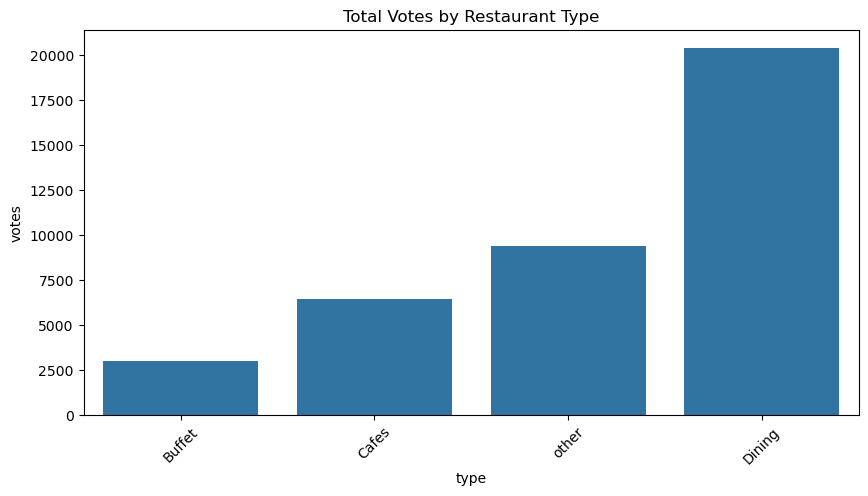

In [11]:


df = pd.read_csv("Zomato data .csv", encoding='latin1')

# Step 2: Rename
df.rename(columns={'listed_in(type)': 'type'}, inplace=True)

# Step 3: Plot
plt.figure(figsize=(10, 5))
sns.barplot(x='type', y='votes', data=df, estimator=sum, errorbar=None)
plt.xticks(rotation=45)
plt.title("Total Votes by Restaurant Type")
plt.show()






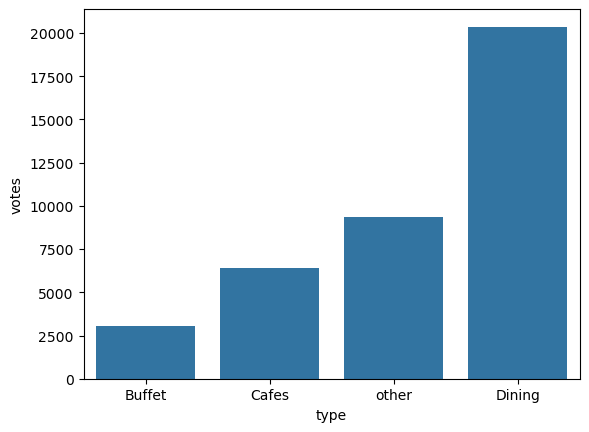

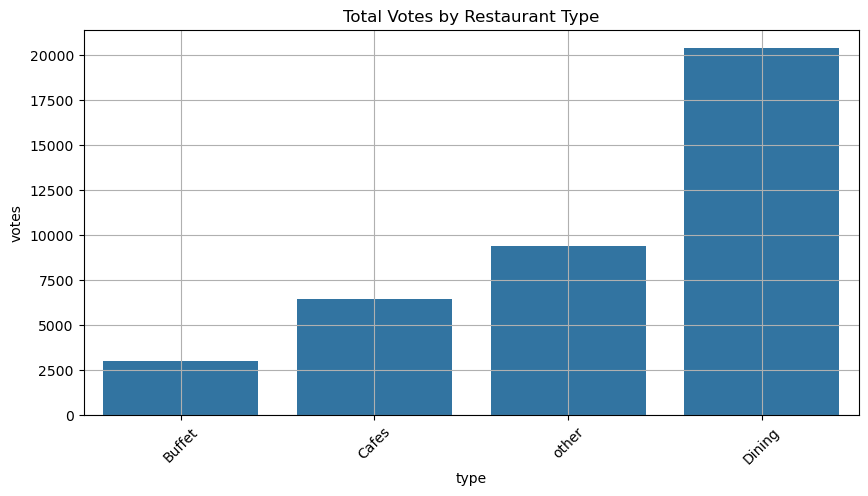

In [12]:
df.rename(columns={'listed_in(type)': 'type'}, inplace=True)
sns.barplot(x='type', y='votes', data=df, estimator=sum, errorbar=None)


# Rename for easier use
df.rename(columns={'listed_in(type)': 'type'}, inplace=True)

# Create plot
plt.figure(figsize=(10, 5))
sns.barplot(x='type', y='votes', data=df, estimator=sum, errorbar=None)
plt.title("Total Votes by Restaurant Type")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()




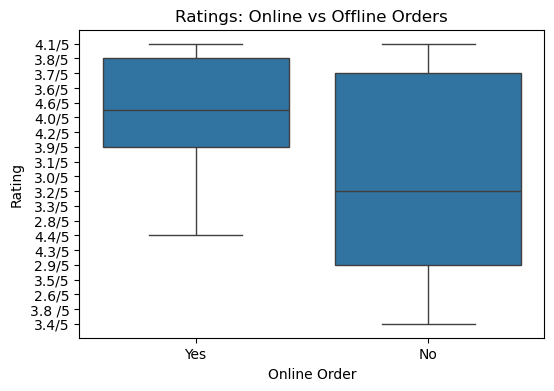

In [13]:
plt.figure(figsize=(6,4))
sns.boxplot(x='online_order', y='rate', data=df)
plt.title("Ratings: Online vs Offline Orders")
plt.ylabel("Rating")
plt.xlabel("Online Order")
plt.show()


C:\Users\VENUX\AppData\Local\Temp\ipykernel_8384\2335142318.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='type', y='votes', data=df, estimator=sum, ci=None)


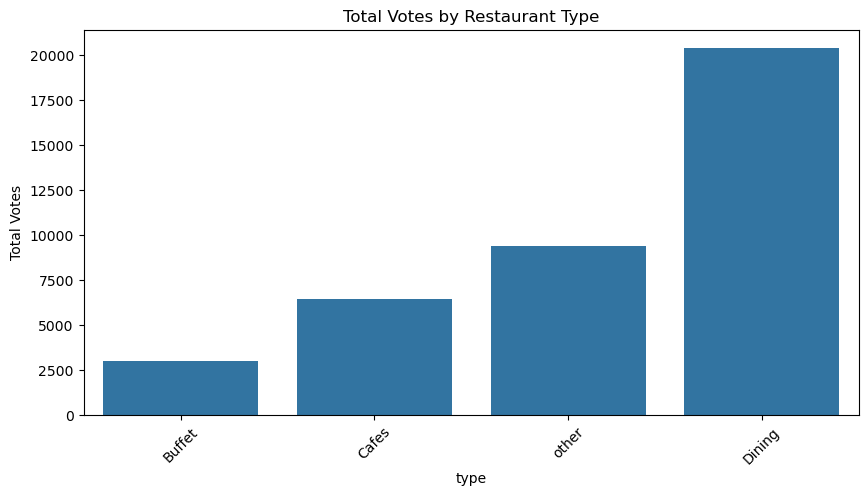

In [14]:
plt.figure(figsize=(10,5))
sns.barplot(x='type', y='votes', data=df, estimator=sum, ci=None)
plt.title("Total Votes by Restaurant Type")
plt.xticks(rotation=45)
plt.ylabel("Total Votes")
plt.show()


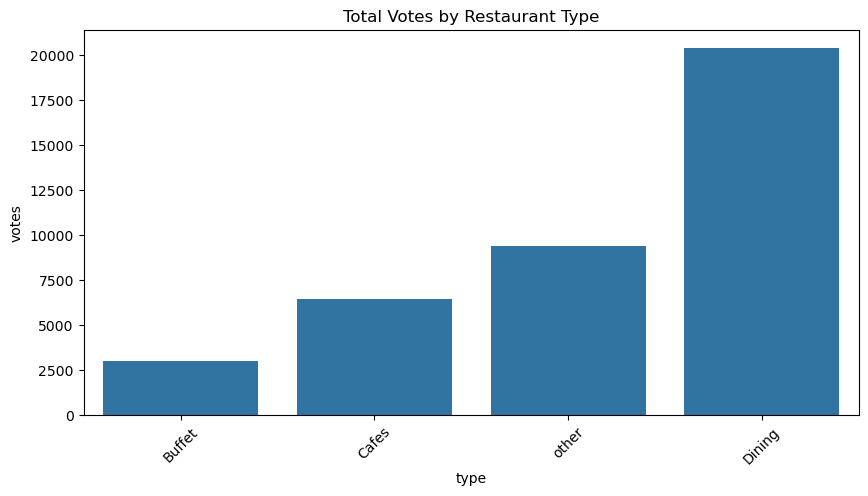

In [15]:

df.rename(columns={'listed_in(type)': 'type'}, inplace=True)

# Create the figure correctly
plt.figure(figsize=(10, 5))
sns.barplot(x='type', y='votes', data=df, estimator=sum, errorbar=None)
plt.xticks(rotation=45)
plt.title("Total Votes by Restaurant Type")
plt.show()





Index(['name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'type'],
      dtype='object')


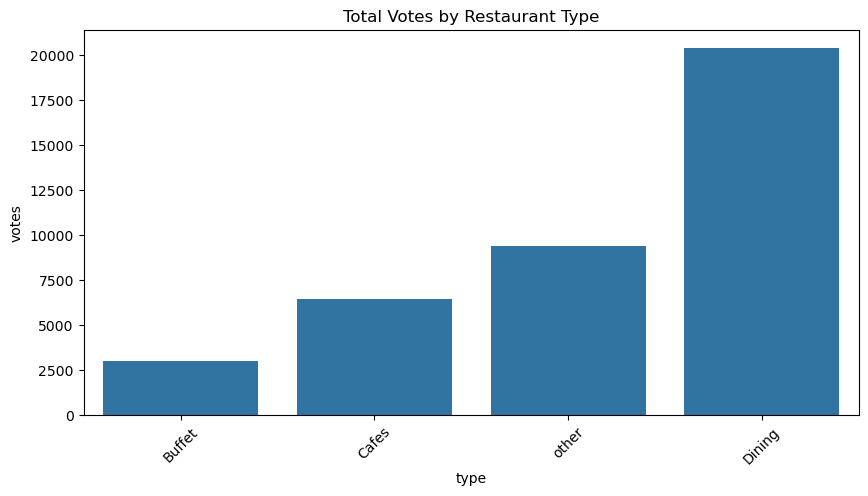

In [16]:
print(df.columns)
'listed_in(type)'

df.rename(columns={'listed_in(type)': 'type'}, inplace=True)

plt.figure(figsize=(10, 5))  # ✅ This is correct
sns.barplot(x='type', y='votes', data=df, estimator=sum, errorbar=None)
plt.xticks(rotation=45)
plt.title("Total Votes by Restaurant Type")
plt.show()

In [17]:
import pandas as pd

# Step 1: Load the dataset
df = pd.read_csv("Zomato data .csv", encoding='latin1')

# Step 2: Rename the column first
df.rename(columns={'listed_in(type)': 'type'}, inplace=True)

# Step 3: Now use 'type'
df['type'].value_counts().head()


type
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64